In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [3]:
df = pd.read_csv("train.csv", sep=",")
print("df head:", df.head(10))

df head:    Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL        65.00     8450   Pave   NaN      Reg   
1   2          20       RL        80.00     9600   Pave   NaN      Reg   
2   3          60       RL        68.00    11250   Pave   NaN      IR1   
3   4          70       RL        60.00     9550   Pave   NaN      IR1   
4   5          60       RL        84.00    14260   Pave   NaN      IR1   
5   6          50       RL        85.00    14115   Pave   NaN      IR1   
6   7          20       RL        75.00    10084   Pave   NaN      Reg   
7   8          60       RL          NaN    10382   Pave   NaN      IR1   
8   9          50       RM        51.00     6120   Pave   NaN      Reg   
9  10         190       RL        50.00     7420   Pave   NaN      Reg   

  LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
0         Lvl    AllPub  ...        0    NaN    NaN         NaN       0   
1         Lvl    AllPub  .

## Zadanie 1.1 - 1.3 statystyki, typy, braki

In [4]:
print("statystyki:", df.describe())

print("typy:", df.dtypes.value_counts())
print("typy kolumn:", df.dtypes)

statystyki:            Id  MSSubClass  LotFrontage   LotArea  OverallQual  OverallCond  \
count 1460.00     1460.00      1201.00   1460.00      1460.00      1460.00   
mean   730.50       56.90        70.05  10516.83         6.10         5.58   
std    421.61       42.30        24.28   9981.26         1.38         1.11   
min      1.00       20.00        21.00   1300.00         1.00         1.00   
25%    365.75       20.00        59.00   7553.50         5.00         5.00   
50%    730.50       50.00        69.00   9478.50         6.00         5.00   
75%   1095.25       70.00        80.00  11601.50         7.00         6.00   
max   1460.00      190.00       313.00 215245.00        10.00         9.00   

       YearBuilt  YearRemodAdd  MasVnrArea  BsmtFinSF1  ...  WoodDeckSF  \
count    1460.00       1460.00     1452.00     1460.00  ...     1460.00   
mean     1971.27       1984.87      103.69      443.64  ...       94.24   
std        30.20         20.65      181.07      456.10  ... 

In [5]:
braki = df.isna().sum()
print("braki:", braki[braki > 0].sort_values(ascending=False))

# MasVnrType ma dużo braków bo pandas czyta "None" jako NaN
df2 = pd.read_csv("train.csv", keep_default_na=False)
print("MasVnrType:", df2["MasVnrType"].value_counts())

braki: PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64
MasVnrType: MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
NA           8
Name: count, dtype: int64


### Jaka jest zmienna docelowa (ang. target variable), którą chcemy przewidywać?:
Zmienna docelowa to SalePrice (cena domu).  

### Jakie rodzaje zmiennych są w zbiorze (liczbowe, kategoryczne, tekstowe)?:
Są kolumny liczbowe (int64 i float64) i tekstowe, które są kategoriami. Niektóre liczbowe też są kategoriami np. OverallQual.

## Zadanie 1.4 wykresy z wykładu

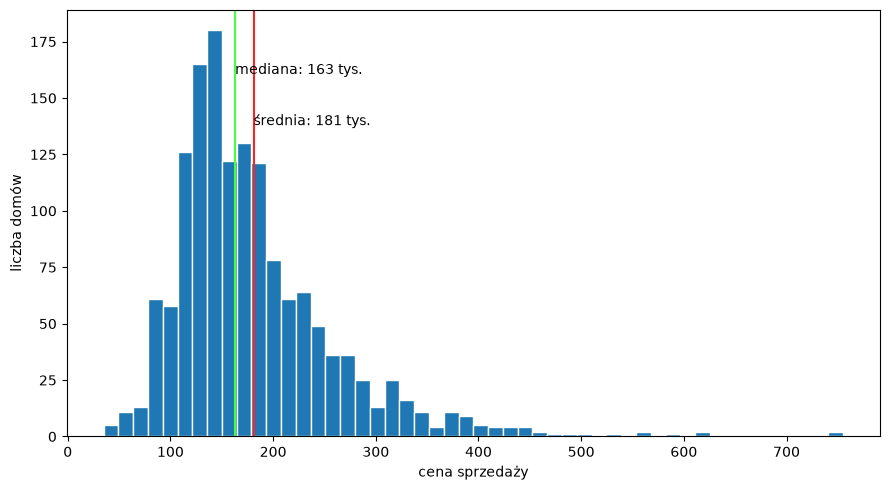

In [6]:
# rozkład cen domów
ceny = df["SalePrice"] / 1000 
mediana = ceny.median()
srednia = ceny.mean()

przedzialy = 50

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(ceny, bins=przedzialy, edgecolor="white")

ax.axvline(mediana, color="#44ff44")
ax.axvline(srednia, color="#ff2222")

ymax = ax.get_ylim()[1]
ax.annotate(f"mediana: {mediana:.0f} tys.", xy=(mediana, ymax * 0.85))
ax.annotate(f"średnia: {srednia:.0f} tys.", xy=(srednia, ymax * 0.73))

ax.set_xlabel("cena sprzedaży")
ax.set_ylabel("liczba domów")

plt.tight_layout()
plt.show()

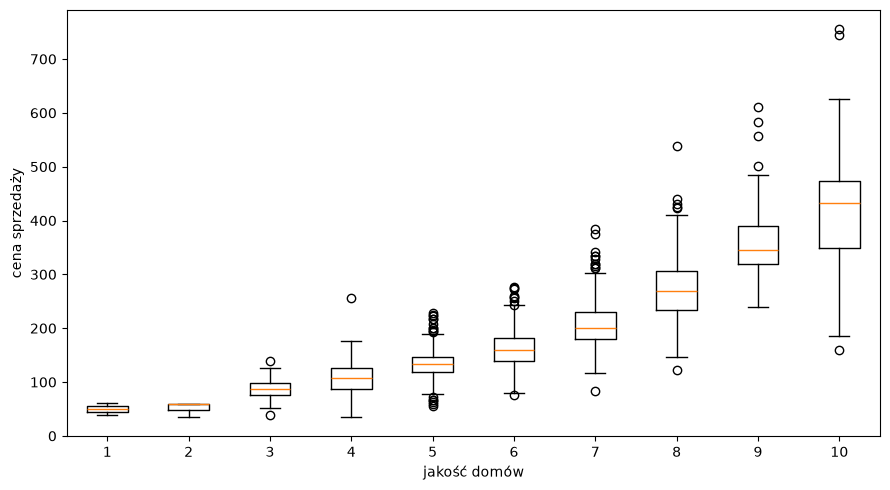

In [7]:
# rozkład cen domów
ceny = df["SalePrice"] / 1000

fig, ax = plt.subplots(figsize=(9, 5))

qualities = []
for i in range(1, 11):
    qualities.append(df[df["OverallQual"] == i]["SalePrice"] / 1000)


ax.boxplot(qualities, tick_labels=range(1,11))

ax.set_xlabel("jakość domów")
ax.set_ylabel("cena sprzedaży")

plt.tight_layout()
plt.show()

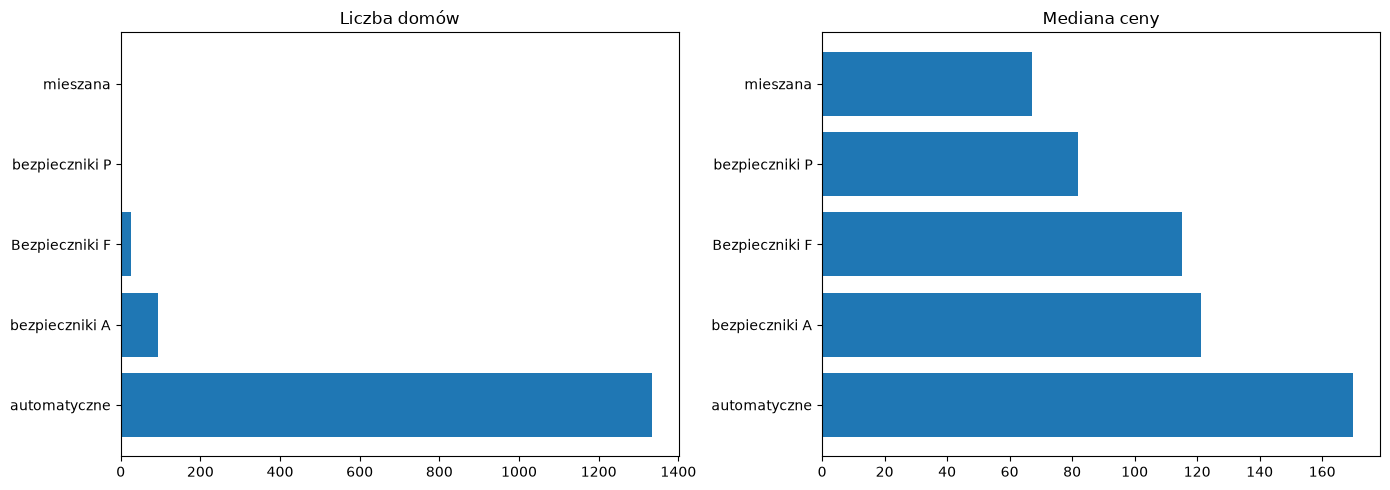

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

nazwy = {
    "SBrkr": "automatyczne",
    "FuseA": "bezpieczniki A",
    "FuseF": "Bezpieczniki F",
    "FuseP": "bezpieczniki P",
    "Mix":   "mieszana"
}


zliczenia = df["Electrical"].value_counts()
etykiety = zliczenia.index.map(nazwy)

ax[0].barh(etykiety, zliczenia.values)

ax[0].set_title("Liczba domów")

ceny = df["SalePrice"] / 1000
mediany = []
for nazwa in zliczenia.index:
    mediany.append(ceny[df["Electrical"] == nazwa].median())

ax[1].barh(etykiety, mediany)

ax[1].set_title("Mediana ceny")

plt.tight_layout()
plt.show()

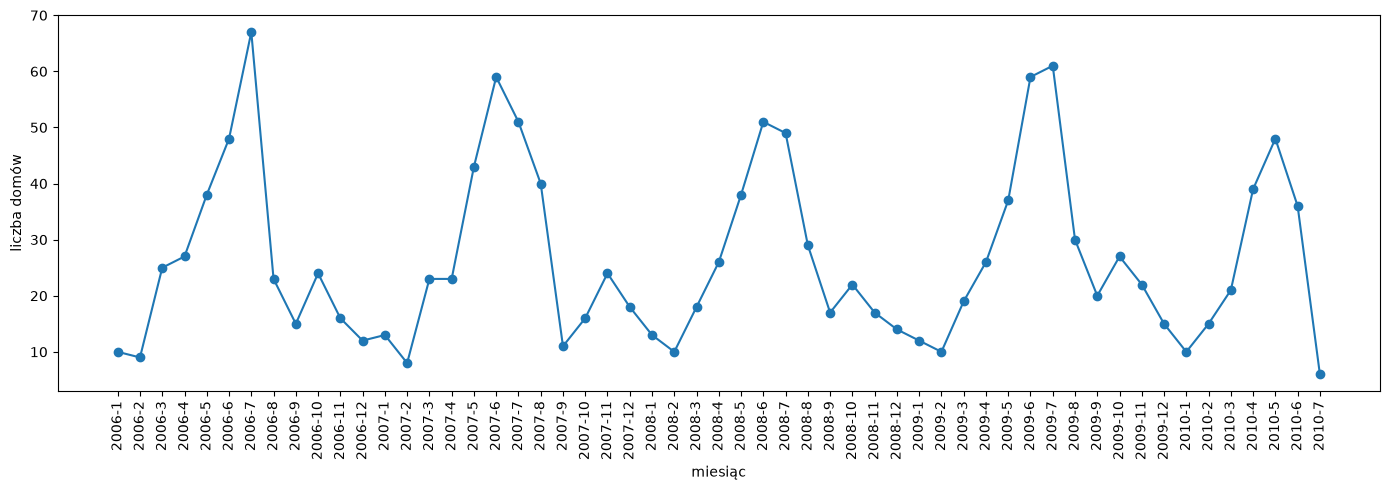

In [9]:
# sprzedaż w miesiącach
sprzedaz = df.groupby(["YrSold", "MoSold"]).size()

miesiace = []
for rok, miesiac in sprzedaz.index:
    miesiace.append(str(rok) + "-" + str(miesiac))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(miesiace, sprzedaz.values, marker="o")
ax.set_xlabel("miesiąc")
ax.set_ylabel("liczba domów")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

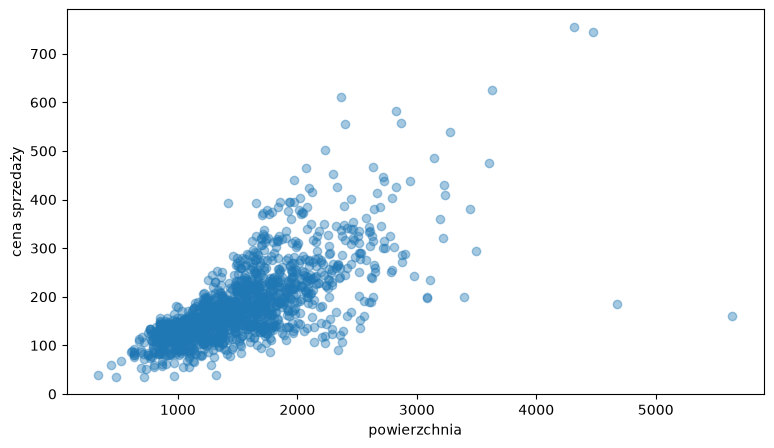

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["GrLivArea"], df["SalePrice"] / 1000, alpha=0.4)
ax.set_xlabel("powierzchnia")
ax.set_ylabel("cena sprzedaży")
plt.show()

## Zadanie 2 analiza zmiennej docelowej

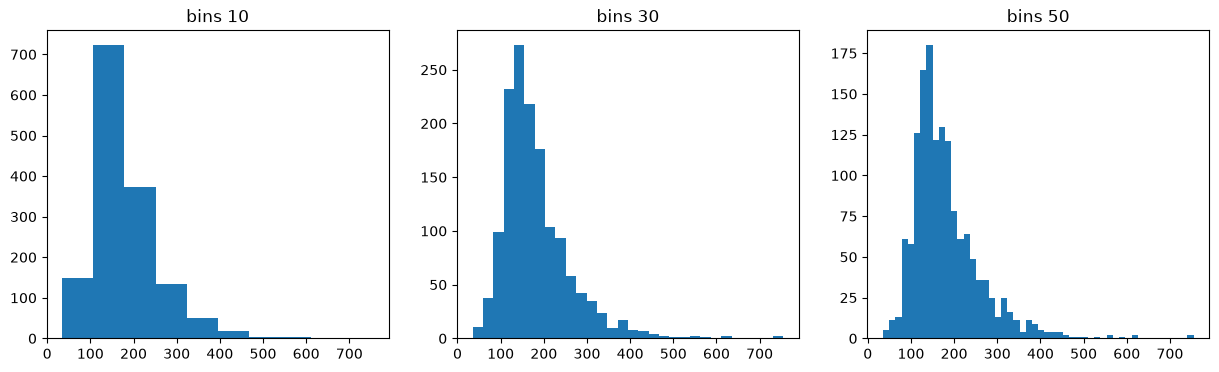

skośność: 1.8828757597682129


In [12]:
ceny = df["SalePrice"] / 1000

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(ceny, bins=10)
ax[0].set_title("bins 10")
ax[1].hist(ceny, bins=30)
ax[1].set_title("bins 30")
ax[2].hist(ceny, bins=50)
ax[2].set_title("bins 50")
plt.show()

print("skośność:", ceny.skew())

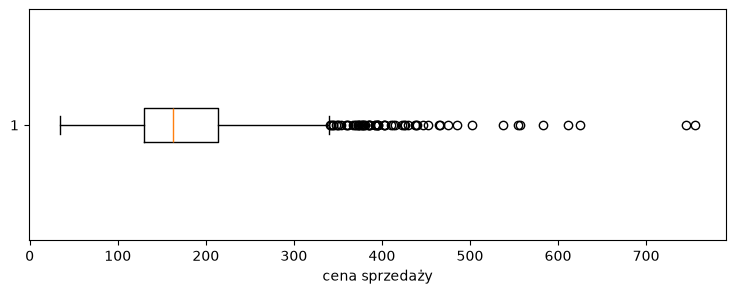

min: 34.9
max: 755.0
średnia: 180.92119589041096
mediana: 163.0
q1: 129.975
q3: 214.0
iqr: 84.025
odstające: 61
jakość drogich: OverallQual
9     23
8     22
10    13
7      3
Name: count, dtype: int64


In [13]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot(ceny, orientation="horizontal")
ax.set_xlabel("cena sprzedaży")
plt.show()

q1 = ceny.quantile(0.25)
q3 = ceny.quantile(0.75)
iqr = q3 - q1
print("min:", ceny.min())
print("max:", ceny.max())
print("średnia:", ceny.mean())
print("mediana:", ceny.median())
print("q1:", q1)
print("q3:", q3)
print("iqr:", iqr)

drogie = df[ceny > q3 + 1.5 * iqr]
print("odstające:", len(drogie))
print("jakość drogich:", drogie["OverallQual"].value_counts())

### Jaki jest rozkład cen?
Rozkład jest prawostronnie skośny.
### Czy są wartości odstające?
wartości odstające to 61 domów powyżej ok. 340 tys.
### Jaka jest średnia i mediana ceny?
średnia: 180.92119589041096
mediana: 163.0
### Czy ceny mają rozkład normalny? (wskazówka: czy histogram jest symetryczny?)
nie, bo jest skośny

## Zadanie 3 - co wpływa na cenę

In [14]:
powierzchnie = []
for kolumna in df.columns:
    if "Area" in kolumna or "SF" in kolumna:
        powierzchnie.append(kolumna)
print("powierzchnie:", powierzchnie)

for kolumna in powierzchnie:
    print(kolumna, df[kolumna].corr(df["SalePrice"]))

powierzchnie: ['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']
LotArea 0.2638433538714056
MasVnrArea 0.4774930470957155
BsmtFinSF1 0.3864198062421531
BsmtFinSF2 -0.011378121450215137
BsmtUnfSF 0.2144791055469689
TotalBsmtSF 0.6135805515591954
1stFlrSF 0.6058521846919145
2ndFlrSF 0.3193338028320677
LowQualFinSF -0.025606130000679548
GrLivArea 0.7086244776126521
GarageArea 0.6234314389183616
WoodDeckSF 0.3244134445681296
OpenPorchSF 0.3158562271160552
PoolArea 0.09240354949187314


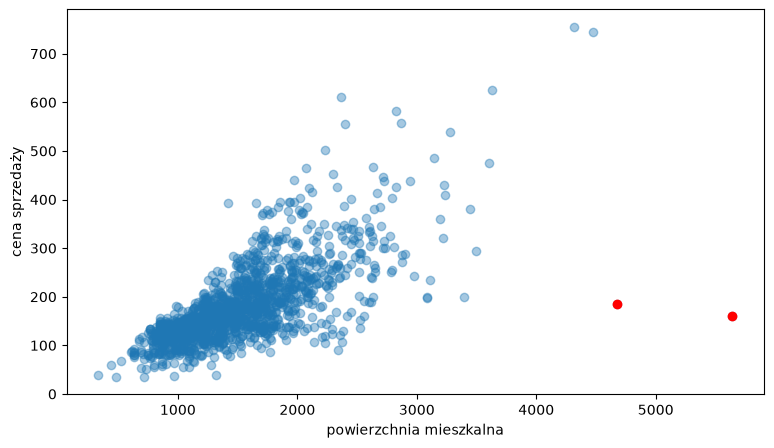

dziwne:         Id  GrLivArea  SalePrice  OverallQual SaleCondition
523    524       4676     184750           10       Partial
1298  1299       5642     160000           10       Partial


In [15]:
dziwne = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["GrLivArea"], df["SalePrice"] / 1000, alpha=0.4)
ax.scatter(dziwne["GrLivArea"], dziwne["SalePrice"] / 1000, color="red")
ax.set_xlabel("powierzchnia mieszkalna")
ax.set_ylabel("cena sprzedaży")
plt.show()

print("dziwne:", dziwne[["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]])

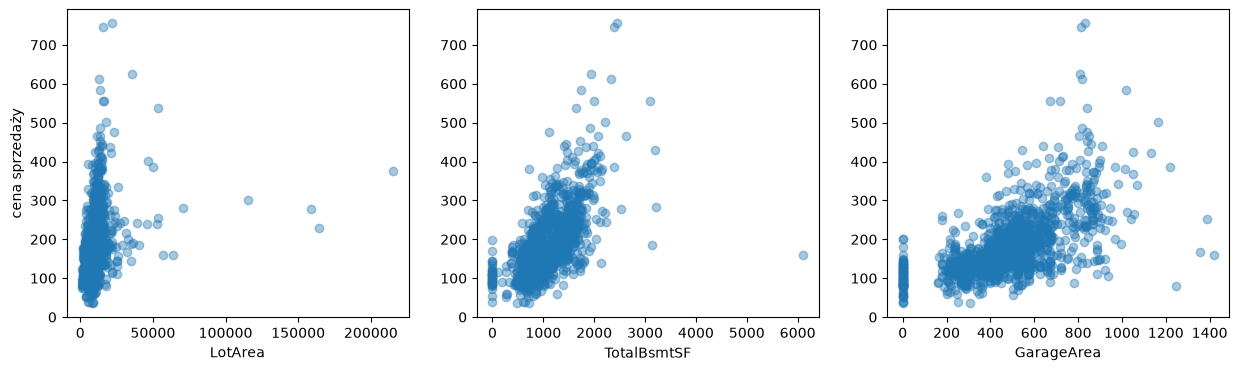

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(df["LotArea"], df["SalePrice"] / 1000, alpha=0.4)
ax[0].set_xlabel("LotArea")
ax[1].scatter(df["TotalBsmtSF"], df["SalePrice"] / 1000, alpha=0.4)
ax[1].set_xlabel("TotalBsmtSF")
ax[2].scatter(df["GarageArea"], df["SalePrice"] / 1000, alpha=0.4)
ax[2].set_xlabel("GarageArea")
ax[0].set_ylabel("cena sprzedaży")
plt.show()

# „Większe domy są droższe”
### Znajdź zmienne związane z powierzchnią (wskazówka: szukaj „Area” i „SF” w nazwach kolumn)
Większe domy są droższe.
zmienne związane z powieżchnią: LotArea, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, GarageArea, WoodDeckSF, OpenPorchSF, PoolArea

### Czy zależność jest wyraźna? Czy jest liniowa?
Tak, zależność jest wyraźna, korelacja GrLivArea z ceną to ok. 0.71.  
Jest mniej więcej liniowa, ale im większy dom tym większy rozrzut cen.

### Czy są dziwne obserwacje? Kim one są?
Dziwne są 2 bardzo duże domy z jakością 10, które są tanie. Mają SaleCondition = Partial, więc to nie jest normalna sprzedaż.